# Problema 1

Na prática de hoje, vamos usar o conjunto de dados "Student Performance" do UCI Machine Learning Repository, que contém informações sobre o desempenho de alunos. Faremos a junção, recombinação e reformatação dos dados usando pandas.

1) Carregar os Dados

Vamos carregar os dados diretamente do URL disponível. O conjunto de dados é dividido em duas partes: informações dos alunos e suas notas.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import zipfile
import io

In [ ]:
pip install requests pandas

In [ ]:
# URL dos dados
url_students = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

# Baixar o arquivo ZIP
response = requests.get(url_students)
response.raise_for_status()  # Verificar se o download foi bem-sucedido

# Extrair os arquivos CSV do ZIP
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    # Ler os dados dos arquivos CSV dentro do ZIP
    with z.open('student-mat.csv') as f_math:
        df_math = pd.read_csv(f_math, sep=';')
    with z.open('student-por.csv') as f_por:
        df_por = pd.read_csv(f_por, sep=';')

Dicionário de Dados para as tabelas do dataset Student Performance

| Variável | Descrição | Tipo | Mensuração | Valores |
| :--- | :--- | :--- | :--- | :--- |
| **school** | Escola do aluno. | Categórico | Texto | 'GP' (Gabriel Pereira) ou 'MS' (Mousinho da Silveira) |
| **sex** | Sexo do aluno. | Categórico (Binário) | Texto | 'F' (Feminino) ou 'M' (Masculino) |
| **age** | Idade do aluno. | Inteiro | Anos | 15 a 22 |
| **address** | Tipo de endereço residencial. | Categórico | Texto | 'U' (Urbano) ou 'R' (Rural) |
| **famsize** | Tamanho da família. | Categórico | Texto | 'LE3' (<= 3) ou 'GT3' (> 3) |
| **Pstatus** | Status de coabitação dos pais. | Categórico | Texto | 'T' (Juntos) ou 'A' (Separados) |
| **Medu** | Nível de escolaridade da mãe. | Inteiro | Nível (Escala) | 0 (Nenhuma) a 4 (Ensino Superior) |
| **Fedu** | Nível de escolaridade do pai. | Inteiro | Nível (Escala) | 0 (Nenhuma) a 4 (Ensino Superior) |
| **Mjob** | Profissão da mãe. | Categórico | Texto | 'teacher', 'health', 'services', 'at_home', 'other' |
| **Fjob** | Profissão do pai. | Categórico | Texto | 'teacher', 'health', 'services', 'at_home', 'other' |
| **reason** | Motivo para escolher a escola. | Categórico | Texto | 'home', 'reputation', 'course', 'other' |
| **guardian** | Responsável legal pelo aluno. | Categórico | Texto | 'mother', 'father' ou 'other' |
| **traveltime** | Tempo de viagem de casa para a escola. | Inteiro | Tempo (Escala) | 1 (<15 min) a 4 (>1 hora) |
| **studytime** | Tempo de estudo semanal. | Inteiro | Tempo (Escala) | 1 (<2 horas) a 4 (>10 horas) |
| **failures** | Número de reprovações anteriores. | Inteiro | Quantidade | 0 a 4 |
| **schoolsup** | Suporte educacional extra. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **famsup** | Suporte educacional da família. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **paid** | Aulas particulares pagas na disciplina. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **activities** | Atividades extracurriculares. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **nursery** | Frequentou a creche/escola maternal. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **higher** | Deseja cursar o ensino superior. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **internet** | Acesso à internet em casa. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **romantic** | Em um relacionamento amoroso. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **famrel** | Qualidade das relações familiares. | Inteiro | Escala de 1 a 5 | 1 (muito ruim) a 5 (excelente) |
| **freetime** | Tempo livre após a escola. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **goout** | Frequência de saídas com amigos. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **Dalc** | Consumo de álcool em dias úteis. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **Walc** | Consumo de álcool aos finais de semana. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **health** | Estado de saúde atual. | Inteiro | Escala de 1 a 5 | 1 (muito ruim) a 5 (muito bom) |
| **absences** | Número de faltas escolares. | Inteiro | Quantidade | 0 a 93 |
| **G1** | Nota do 1º período. | Inteiro | Nota (Pontos) | 0 a 20 |
| **G2** | Nota do 2º período. | Inteiro | Nota (Pontos) | 0 a 20 |
| **G3** | Nota final (variável alvo). | Inteiro | Nota (Pontos) | 0 a 20 |

Análise Exploratória Inicial nas duas bases

## Matemática

In [ ]:
print(df_math.head())
print(df_math.tail())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
390     M

In [ ]:
df_math.shape

(395, 33)

In [ ]:
df_math.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
df_math.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [ ]:
print(df_math.isnull().sum())
print(f"\n Número de valores duplicados no DataFrame de matemática: {df_math.duplicated().sum()}")

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

 Número de valores duplicados no DataFrame de matemática: 0


## Português

In [ ]:
print(df_por.head())
print(df_por.tail())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
644     M

In [ ]:
df_por.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [ ]:
df_por.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [ ]:
print(df_por.isnull().sum())
print(f"\n Número de valores duplicados no DataFrame de matemática: {df_por.duplicated().sum()}")

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

 Número de valores duplicados no DataFrame de matemática: 0


# 2) Junção dos DataFrames

Vamos juntar os DataFrames de matemática e português com base no ID dos alunos.

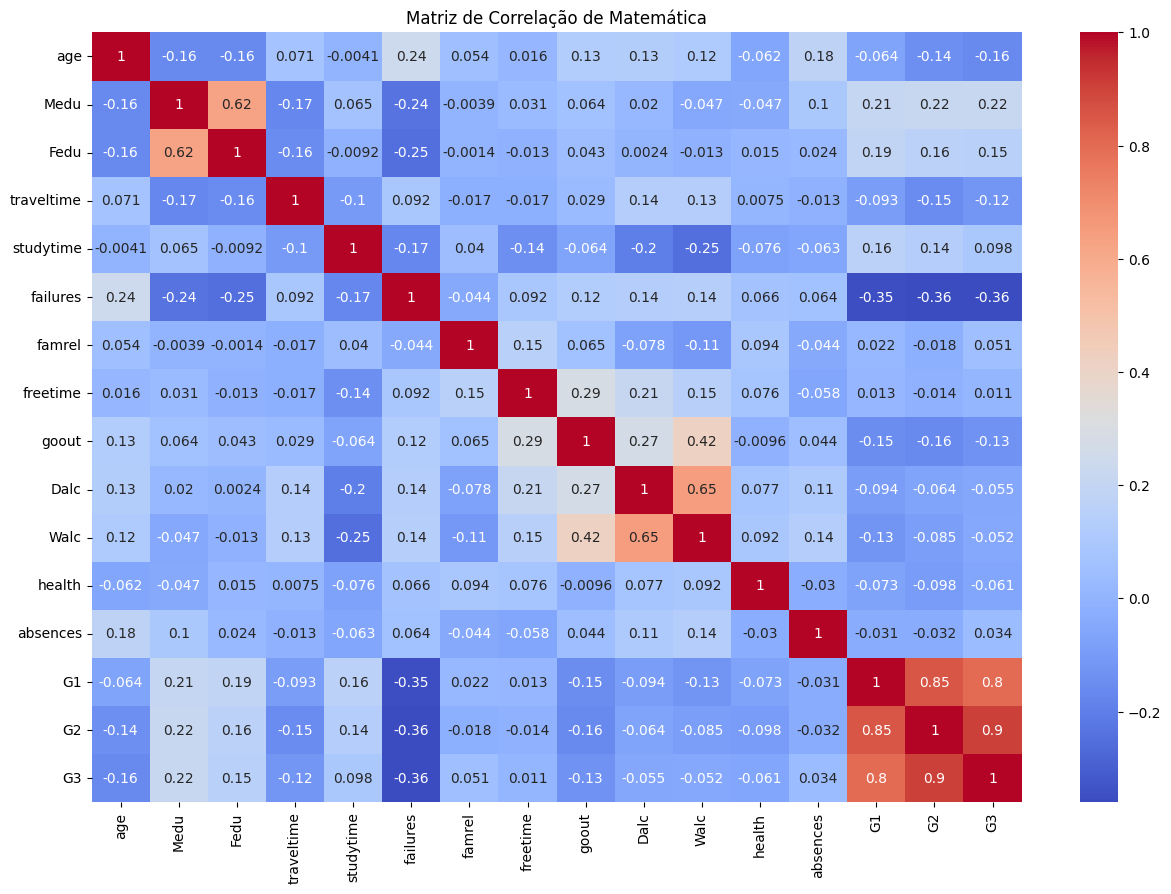

In [ ]:
# Calcular e visualizar a matriz de correlação de Matemática
plt.figure(figsize=(15, 10))
corr = df_math[['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
                'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação de Matemática')
plt.show()


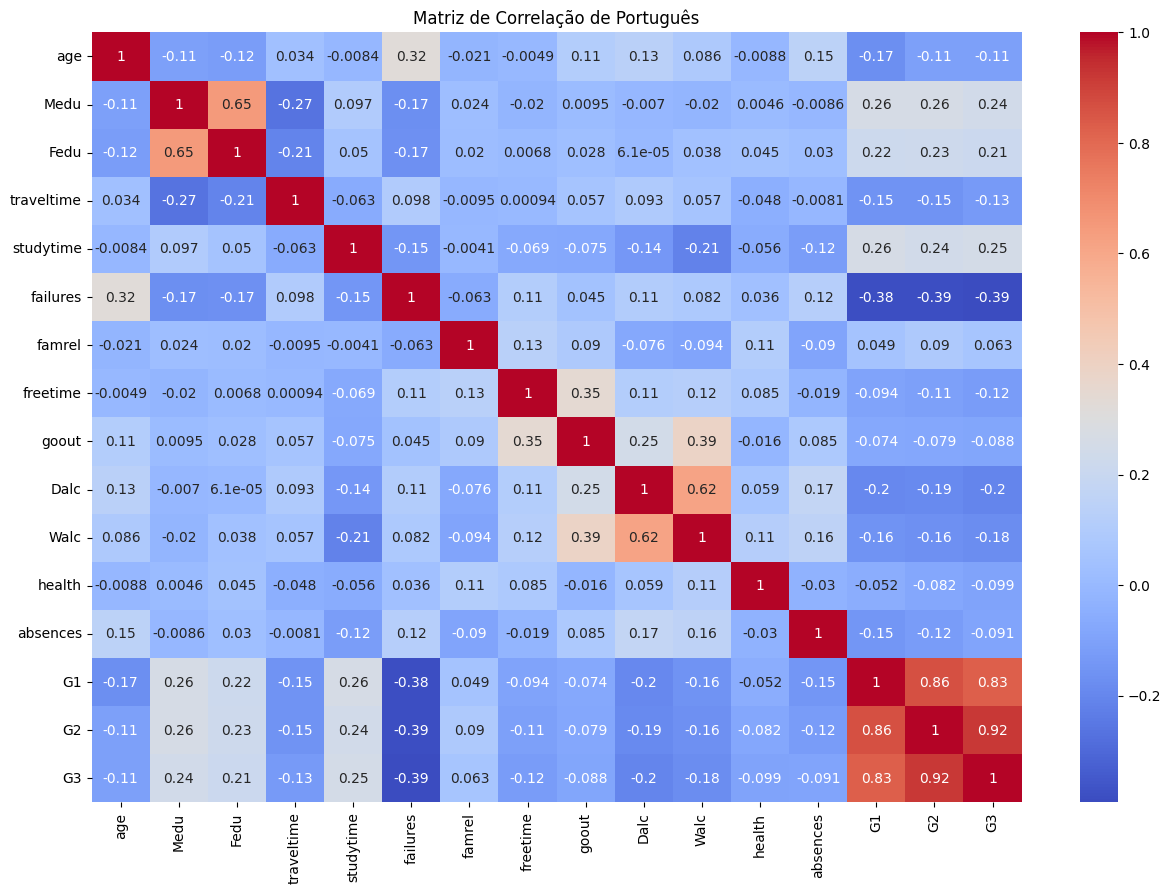

In [ ]:
# Calcular e visualizar a matriz de correlação de Português
plt.figure(figsize=(15, 10))
corr = df_por[['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
                'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação de Português')
plt.show()

## Criar um ID por Chave Composta (Atributos Demográficos)
Como um mesmo aluno pode ter feito ambas as disciplinas, a lógica para identificá-lo é combinar as variáveis demográficas e socioeconômicas que não mudam entre as matérias (como escola, sexo, idade, profissão dos pais, etc.).

É possível identificar alunos idênticos combinando 13 colunas demográficas:

In [ ]:
# Lista de colunas que identificam unicamente o aluno
colunas_id = [
    'school', 'sex', 'age', 'address', 'famsize', 'Pstatus',
    'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'nursery', 'internet'
]

# Junção dos DataFrames mantendo apenas alunos presentes em ambos os cursos (Inner Join)
df_merged = pd.merge(df_math, df_por, on=colunas_id, suffixes=('_math', '_por'))

In [ ]:
df_merged.columns.to_list()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian_math',
 'traveltime_math',
 'studytime_math',
 'failures_math',
 'schoolsup_math',
 'famsup_math',
 'paid_math',
 'activities_math',
 'nursery',
 'higher_math',
 'internet',
 'romantic_math',
 'famrel_math',
 'freetime_math',
 'goout_math',
 'Dalc_math',
 'Walc_math',
 'health_math',
 'absences_math',
 'G1_math',
 'G2_math',
 'G3_math',
 'guardian_por',
 'traveltime_por',
 'studytime_por',
 'failures_por',
 'schoolsup_por',
 'famsup_por',
 'paid_por',
 'activities_por',
 'higher_por',
 'romantic_por',
 'famrel_por',
 'freetime_por',
 'goout_por',
 'Dalc_por',
 'Walc_por',
 'health_por',
 'absences_por',
 'G1_por',
 'G2_por',
 'G3_por']

In [ ]:
df_merged.info()
# nesse caso eu criei um DataFrame com apenas os alunos que se repetem entre as tabelas das duas disciplinas (Math e Por)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 382 entries, 0 to 381
Data columns (total 53 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   school           382 non-null    object
 1   sex              382 non-null    object
 2   age              382 non-null    int64 
 3   address          382 non-null    object
 4   famsize          382 non-null    object
 5   Pstatus          382 non-null    object
 6   Medu             382 non-null    int64 
 7   Fedu             382 non-null    int64 
 8   Mjob             382 non-null    object
 9   Fjob             382 non-null    object
 10  reason           382 non-null    object
 11  guardian_math    382 non-null    object
 12  traveltime_math  382 non-null    int64 
 13  studytime_math   382 non-null    int64 
 14  failures_math    382 non-null    int64 
 15  schoolsup_math   382 non-null    object
 16  famsup_math      382 non-null    object
 17  paid_math        382 non-null    ob

In [ ]:
df_merged.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel_por,freetime_por,goout_por,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [ ]:
print(df_math.shape)
print(df_por.shape)

(395, 33)
(649, 33)


In [ ]:
df_merged['student_id'] = [i for i in range(1, len(df_merged) + 1)]
# criando um ID calculado que vai de 1 até 382 (tamanho do DataFrame)

In [ ]:
df_merged

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime_por,goout_por,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por,student_id
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,3
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,4
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377,MS,F,18,U,LE3,T,3,1,teacher,services,...,3,4,1,1,1,4,15,15,16,378
378,MS,F,18,U,GT3,T,1,1,other,other,...,4,4,2,2,5,3,7,8,7,379
379,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,5,6,11,12,9,380
380,MS,M,17,U,LE3,T,3,1,services,services,...,4,5,3,4,2,6,10,10,10,381


# 3) Recombinação dos Dados
Vamos calcular a média das notas em ambas as disciplinas.

In [ ]:
df_merged['avg_math_grade'] = round(((df_merged['G1_math'] + df_merged['G2_math'] + df_merged['G3_math'])/3) , 2)

df_merged['avg_math_grade'].head()

,avg_math_grade
0,5.67
1,5.33
2,8.33
3,14.67
4,8.67


In [ ]:
df_merged['avg_por_grade'] = round(((df_merged['G1_por'] + df_merged['G2_por'] + df_merged['G3_por'])/3) , 2)

df_merged['avg_por_grade'].head()

,avg_por_grade
0,7.33
1,10.33
2,12.33
3,14.00
4,12.33


In [ ]:
df_merged.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por,student_id,avg_math_grade,avg_por_grade
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,1,1,3,4,0,11,11,1,5.67,7.33
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,1,1,3,2,9,11,11,2,5.33,10.33
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,2,3,3,6,12,13,12,3,8.33,12.33
3,GP,F,15,U,GT3,T,4,2,health,services,...,1,1,5,0,14,14,14,4,14.67,14.00
4,GP,F,16,U,GT3,T,3,3,other,other,...,1,2,5,0,11,13,13,5,8.67,12.33
5,GP,M,16,U,LE3,T,4,3,services,other,...,1,2,5,6,12,12,13,6,15.00,12.33
6,GP,M,16,U,LE3,T,2,2,other,other,...,1,1,3,0,13,12,13,7,11.67,12.67
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,1,1,1,2,10,13,13,8,5.67,12.00
8,GP,M,15,U,LE3,A,3,2,services,other,...,1,1,1,0,15,16,17,9,17.67,16.00
9,GP,M,15,U,GT3,T,3,4,other,other,...,1,1,5,0,12,12,13,10,14.67,12.33


# 4)  Reformatação dos Dados
Vamos reformular os dados para que as notas de cada disciplina sejam representadas em um formato mais visual.

In [ ]:
pivot_df = df_merged.pivot(index='student_id', columns='school',
                           values=['G1_math', 'G2_math', 'G3_math', 'G1_por', 'G2_por', 'G3_por', 'avg_math_grade', 'avg_por_grade'])

In [ ]:
pivot_df
# agora sim!
# estou exibindo as notas e as médias das notas de cada disciplina de cada aluno em um DataFrame pivotado

G1_math       G2_math       G3_math       G1_por       G2_por  \
school          GP    MS      GP    MS      GP    MS     GP    MS     GP   
student_id                                                                 
1              5.0   NaN     6.0   NaN     6.0   NaN    0.0   NaN   11.0   
2              5.0   NaN     5.0   NaN     6.0   NaN    9.0   NaN   11.0   
3              7.0   NaN     8.0   NaN    10.0   NaN   12.0   NaN   13.0   
4             15.0   NaN    14.0   NaN    15.0   NaN   14.0   NaN   14.0   
5              6.0   NaN    10.0   NaN    10.0   NaN   11.0   NaN   13.0   
...            ...   ...     ...   ...     ...   ...    ...   ...    ...   
378            NaN   7.0     NaN   9.0     NaN   8.0    NaN  15.0    NaN   
379            NaN   6.0     NaN   5.0     NaN   0.0    NaN   7.0    NaN   
380            NaN   6.0     NaN   5.0     NaN   0.0    NaN  11.0    NaN   
381            NaN  14.0     NaN  16.0     NaN  16.0    NaN  10.0    NaN   
382            NaN  11.0     NaN  12.0     NaN  10.0    NaN  10.0    NaN   

                 G3_por       avg_math_grade        avg_por_grade         
school        MS     GP    MS             GP     MS            GP     MS  
student_id                                                                
1            NaN   11.0   NaN           5.67    NaN          7.33    NaN  
2            NaN   11.0   NaN           5.33    NaN         10.33    NaN  
3            NaN   12.0   NaN           8.33    NaN         12.33    NaN  
4            NaN   14.0   NaN          14.67    NaN         14.00    NaN  
5            NaN   13.0   NaN           8.67    NaN         12.33    NaN  
...          ...    ...   ...            ...    ...           ...    ...  
378         15.0    NaN  16.0            NaN   8.00           NaN  15.33  
379          8.0    NaN   7.0            NaN   3.67           NaN   7.33  
380         12.0    NaN   9.0            NaN   3.67           NaN  10.67  
381         10.0    NaN  10.0            NaN  15.33           NaN  10.00  
382         11.0    NaN  11.0            NaN  11.00           NaN  10.67  

[382 rows x 16 columns]

In [ ]:
pivot_df_menor = df_merged.pivot(index='student_id', columns='school',
                           values=['avg_math_grade', 'avg_por_grade'])

In [ ]:
pivot_df_menor
# cada aluno só pode pertencer a uma escola, portanto as notas de cada um so aparecem em uma coluna!

avg_math_grade        avg_por_grade       
school                 GP     MS            GP     MS
student_id                                           
1                    5.67    NaN          7.33    NaN
2                    5.33    NaN         10.33    NaN
3                    8.33    NaN         12.33    NaN
4                   14.67    NaN         14.00    NaN
5                    8.67    NaN         12.33    NaN
...                   ...    ...           ...    ...
378                   NaN   8.00           NaN  15.33
379                   NaN   3.67           NaN   7.33
380                   NaN   3.67           NaN  10.67
381                   NaN  15.33           NaN  10.00
382                   NaN  11.00           NaN  10.67

[382 rows x 4 columns]

Para isso, criarei um critério de aprovação.

Vou usar a média de aprovação como 12 pontos. Se for menor o aluno foi reprovado, se for maior ou igual o aluno foi aprovado.

In [ ]:
import numpy as np

df_merged['math_status'] = np.where(df_merged['avg_math_grade'] < 12, 'reprovado', 'aprovado')

In [ ]:
print(df_merged['math_status'].head(10))
print('\n')
print(df_merged['math_status'].value_counts())

0    reprovado
1    reprovado
2    reprovado
3     aprovado
4    reprovado
5     aprovado
6    reprovado
7    reprovado
8     aprovado
9     aprovado
Name: math_status, dtype: object


math_status
reprovado    235
aprovado     147
Name: count, dtype: int64


In [ ]:
df_merged['por_status'] = np.where(df_merged['avg_por_grade'] < 12, 'reprovado', 'aprovado')

In [ ]:
print(df_merged['por_status'].head(10))
print('\n')
print(df_merged['por_status'].value_counts())

0    reprovado
1    reprovado
2     aprovado
3     aprovado
4     aprovado
5     aprovado
6     aprovado
7     aprovado
8     aprovado
9     aprovado
Name: por_status, dtype: object


por_status
aprovado     220
reprovado    162
Name: count, dtype: int64


/tmp/ipykernel_1419/737344445.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='avg_math_grade', y='math_status', data=df_merged, palette='mako')


<Axes: xlabel='avg_math_grade', ylabel='math_status'>

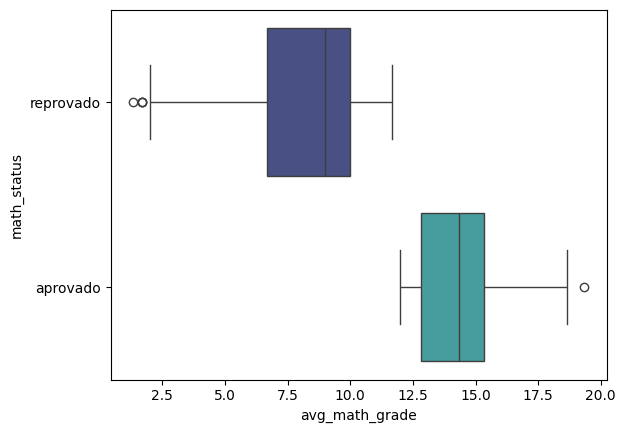

In [ ]:
# plotando os alunos aprovados vs reprovados em um boxplot
sns.boxplot(x='avg_math_grade', y='math_status', data=df_merged, palette='mako')

/tmp/ipykernel_1419/3068086903.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='avg_por_grade', y='por_status', data=df_merged, palette='magma')


<Axes: xlabel='avg_por_grade', ylabel='por_status'>

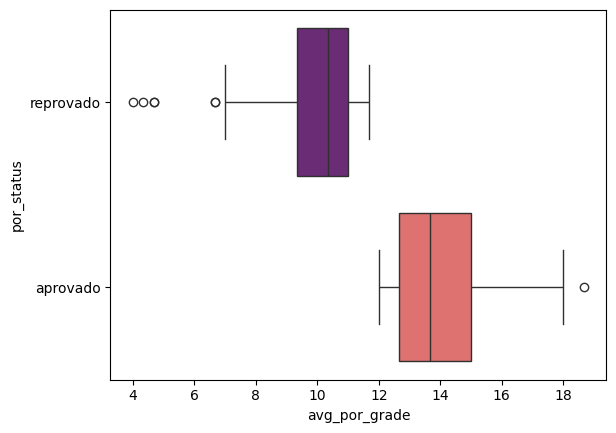

In [ ]:
# plotando os alunos aprovados vs reprovados em um boxplot
sns.boxplot(x='avg_por_grade', y='por_status', data=df_merged, palette='magma')

In [ ]:
df_math_approved = df_merged.groupby('school')['math_status'].value_counts(normalize=True) * 100
df_math_approved

school  math_status
GP      reprovado      60.526316
        aprovado       39.473684
MS      reprovado      70.000000
        aprovado       30.000000
Name: proportion, dtype: float64

In [ ]:
df_por_approved = df_merged.groupby('school')['por_status'].value_counts(normalize=True) * 100
df_por_approved

school  por_status
GP      aprovado      59.94152
        reprovado     40.05848
MS      reprovado     62.50000
        aprovado      37.50000
Name: proportion, dtype: float64

/tmp/ipykernel_1419/1872170067.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='math_status', y='absences_math', data=df_merged, palette='tab10')


<Axes: xlabel='math_status', ylabel='absences_math'>

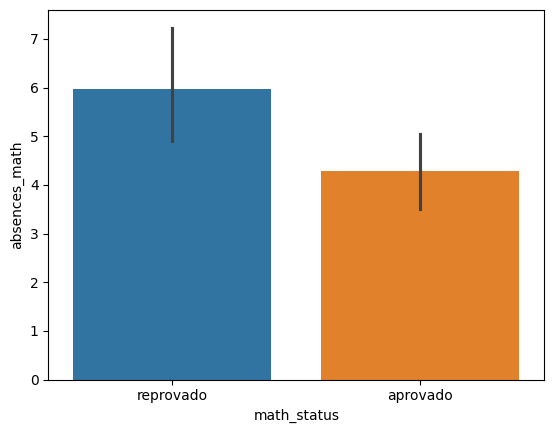

In [ ]:
sns.barplot(x='math_status', y='absences_math', data=df_merged, palette='tab10')